<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [scikit-bio](https://github.com/Query-farm/vgi-scikit-bio)

Bioinformatics functions for sequence analysis, alignment, microbial diversity, ordination and phylogenetic trees.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-scikit-bio/blob/main/notebooks/03_comparison_depends_on_representation.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-scikit-bio/blob/main/notebooks/README.md)


## 03 · A base change is not a protein change

Do equal nucleotide mismatch counts imply equal changes in a translated string? We compare authored coding-string variants, retain an unequal-length deletion as an explicit Hamming boundary, and inspect alignments before interpreting their scores.

These **synthetic strings** have a stipulated frame and standard genetic code. They are not genes from an organism, annotations, mutation-impact predictions or medical evidence. `ALIGNMENT_MODE` is **"global"** by default; the experiment selects **"local"**. Raw strings and scalar global scores stay fixed.

In [1]:
ALIGNMENT_MODE = "global"  # experiment: "local"

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.29":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.29"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the kernel, then run all cells.")

from vgi_notebooks import check_runtime  # noqa: E402

check_runtime()

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import connect
from vgi_notebooks.presentation import finish, prose, theme

if ALIGNMENT_MODE not in ("global", "local"):
    raise ValueError("ALIGNMENT_MODE must be global or local.")
theme()
session = connect(globals())
Path("artifacts").mkdir(exist_ok=True)
SOURCE = "Source: authored synthetic inputs · actual vgi-scikit-bio v0.3.0 worker · no biological inference"

### Connect to the released scientific worker

The short literal Git-tag launcher uses **v0.3.0** in a separate Python 3.13 process. Its release owns scientific and protocol dependencies; no source checkout or transitive overrides are needed. The notebook kernel uses the shared base package. First use downloads the worker and VGI; all analytical inputs below are synthetic and local. Shared connection setup creates an empty temporary SQL secret directory and disables persistent secrets.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'skbio' (TYPE vgi,
 LOCATION 'uvx --python 3.13 --from git+https://github.com/Query-farm/vgi-scikit-bio@v0.3.0 vgi-scikit-bio');

,Success


### Count positions only when the strings have equal lengths

`hamming_distance`, `mismatch_count` and `match_count` compare positions, not a fitted alignment. Their NULL result for unequal lengths means this comparison is unavailable, not zero difference. We retain the codon deletion and flanked string in the audit and use an alignment for those cases.

In [5]:
%%sql
CREATE TABLE pairs AS SELECT variant,'ATGCGGATTACAAAA' AS reference,alternative
FROM (VALUES
 ('unchanged','ATGCGGATTACAAAA'),
 ('synonymous','ATGCGTATTACAAAA'),
 ('amino_acid_change','ATGCGGATTCCAAAA'),
 ('codon_deletion','ATGATTACAAAA'),
 ('flanked','TTTATGCGGATTACAAAAGGG')
) AS p(variant,alternative);
CREATE TABLE positions AS SELECT *,length(reference) AS reference_bases,length(alternative) AS alternative_bases,
 skbio.sequence.hamming_distance(reference,alternative) AS hamming_fraction,
 skbio.sequence.mismatch_count(reference,alternative) AS mismatches,
 skbio.sequence.match_count(reference,alternative) AS matches,
 skbio.alignment.align_score_nucleotide(reference,alternative) AS global_dna_score
FROM pairs;
SELECT variant,reference_bases,alternative_bases,matches,mismatches,hamming_fraction,global_dna_score
FROM positions ORDER BY variant;

,variant,reference_bases,alternative_bases,matches,mismatches,hamming_fraction,global_dna_score
0,amino_acid_change,15,15,14,1,0.066667,12.0
1,codon_deletion,15,12,<NA>,<NA>,NaN,6.0
2,flanked,15,21,<NA>,<NA>,NaN,15.0
3,synonymous,15,15,14,1,0.066667,12.0
4,unchanged,15,15,15,0,0.000000,15.0


The synonymous and amino-acid-change rows each differ at one of 15 positions. The deletion and flanked strings have unequal lengths, so positional distances stay NULL. Their successful global alignment scores answer a different question; a score is tied to this worker's scoring and end-gap defaults, not a calibrated probability.

### Inspect selected alignments beside a fixed global reference

Materialize global and selected alignments separately. The table function exposes aligned strings and aligned length; the scalar's global score should agree with the fixed global table. This worker passes through the legacy aligner's defaults. Global nucleotide mode rewards a match by **+1** and a mismatch by **−2**; local mode uses **+2** and **−3**. Both use gap-opening/extension penalties of 5/2, and global mode leaves terminal gaps unpenalized.

Changing mode therefore changes both the algorithm and the nucleotide scoring settings. Local mode can select a matching subregion, but a higher local score can also come from its larger match reward. Compare aligned strings and column counts; scores across modes do not measure improvement under one fixed objective.

In [6]:
%%sql
CREATE TABLE dna_global AS SELECT * FROM skbio.alignment.pairwise_align_nucleotide(
 (SELECT variant,reference,alternative FROM pairs ORDER BY variant),id := 'variant',seq1 := 'reference',seq2 := 'alternative',mode := 'global');
CREATE TABLE dna_selected AS SELECT * FROM skbio.alignment.pairwise_align_nucleotide(
 (SELECT variant,reference,alternative FROM pairs ORDER BY variant),id := 'variant',seq1 := 'reference',seq2 := 'alternative',mode := '{{ALIGNMENT_MODE}}');
SELECT variant,aligned_1,aligned_2,score,length AS aligned_columns FROM dna_selected ORDER BY variant;

,variant,aligned_1,aligned_2,score,aligned_columns
0,amino_acid_change,ATGCGGATTACAAAA,ATGCGGATTCCAAAA,12.0,15
1,codon_deletion,ATGCGGATTACAAAA,---ATGATTACAAAA,6.0,15
2,flanked,---ATGCGGATTACAAAA---,TTTATGCGGATTACAAAAGGG,15.0,21
3,synonymous,ATGCGGATTACAAAA,ATGCGTATTACAAAA,12.0,15
4,unchanged,ATGCGGATTACAAAA,ATGCGGATTACAAAA,15.0,15


In [7]:
%%sql alignment <<
SELECT p.variant,p.matches,p.mismatches,p.hamming_fraction,p.global_dna_score,
 g.length AS global_columns,s.length AS selected_columns,s.score AS selected_score,
 g.aligned_1 AS global_reference,g.aligned_2 AS global_alternative,
 s.aligned_1 AS selected_reference,s.aligned_2 AS selected_alternative
FROM positions p JOIN dna_global g USING(variant) JOIN dna_selected s USING(variant) ORDER BY variant;

,variant,global_dna_score,selected_score,global_columns,selected_columns
0,amino_acid_change,12.0,12.0,15,15
1,codon_deletion,6.0,6.0,15,15
2,flanked,15.0,15.0,21,21
3,synonymous,12.0,12.0,15,15
4,unchanged,15.0,15.0,15,15


Selected **global** mode shortens **0 of 5** alignments relative to the fixed global result. The unequal-length inputs remain visible. A shortened aligned region is a changed comparison span, not evidence that the omitted bases disappeared. For the unchanged string pair, the fixed global score is **15** and the selected score is **15**. The local-mode experiment doubles the per-match reward; that increase does not indicate a closer biological match.

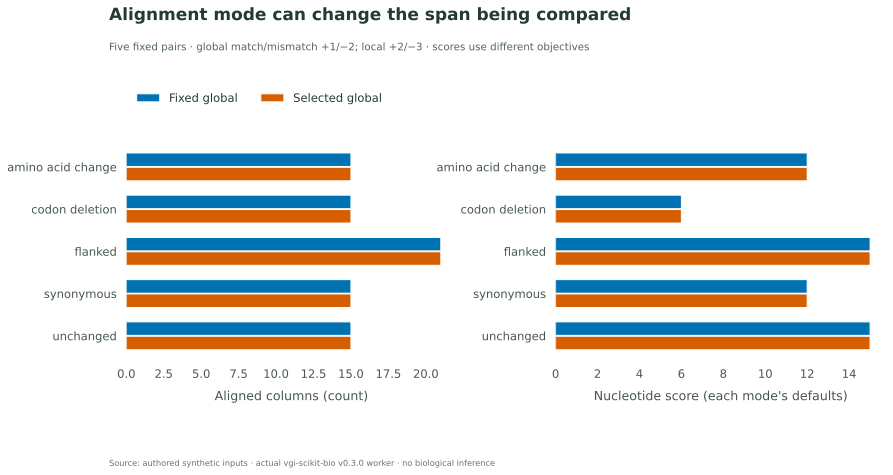

In [8]:
display(
    alignment[
        ["variant", "global_dna_score", "selected_score", "global_columns", "selected_columns"]
    ]
)
shortened = int((alignment.selected_columns < alignment.global_columns).sum())
unchanged = alignment[alignment.variant == "unchanged"].iloc[0]
prose(
    f"Selected **{ALIGNMENT_MODE}** mode shortens **{shortened} of {len(alignment)}** alignments relative to the fixed global result. The unequal-length inputs remain visible. A shortened aligned region is a changed comparison span, not evidence that the omitted bases disappeared. For the unchanged string pair, the fixed global score is **{unchanged.global_dna_score:g}** and the selected score is **{unchanged.selected_score:g}**. The local-mode experiment doubles the per-match reward; that increase does not indicate a closer biological match."
)
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
y = np.arange(len(alignment))
labels = alignment.variant.str.replace("_", " ")
for ax, a, b, label in [
    (axes[0], alignment.global_columns, alignment.selected_columns, "Aligned columns (count)"),
    (
        axes[1],
        alignment.global_dna_score,
        alignment.selected_score,
        "Nucleotide score (each mode's defaults)",
    ),
]:
    ax.barh(y - 0.17, a, height=0.32, label="Fixed global", color="#0072B2")
    ax.barh(y + 0.17, b, height=0.32, label=f"Selected {ALIGNMENT_MODE}", color="#D55E00")
    ax.set_yticks(y, labels)
    ax.set_xlabel(label)
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.09, 0.82), ncol=2)
finish(
    fig,
    "Alignment mode can change the span being compared",
    "Five fixed pairs · global match/mismatch +1/−2; local +2/−3 · scores use different objectives",
    SOURCE,
    name=f"alignment-{ALIGNMENT_MODE}",
)

### Translate a stipulated frame, then compare the resulting proteins

Translation here starts at the first base under the standard code. The codon deletion removes three bases, so the stipulated frame is retained. We exclude the flanked string from this translation comparison because its intended coding region was not specified. `is_valid_protein` validates the resulting alphabet; a pure A/C/G/T string also passes protein validation, so that predicate cannot identify which molecule a string represents.

The protein scalar and table functions use protein scoring defaults. Their scores must agree with each other, but cannot be compared numerically to nucleotide scores. Both global and selected protein alignments are shown.

In [9]:
%%sql
CREATE TABLE translated AS SELECT variant,
 skbio.sequence.translate(reference) AS reference_protein,
 skbio.sequence.translate(alternative) AS alternative_protein
FROM pairs WHERE variant<>'flanked';
CREATE TABLE protein_summary AS SELECT *,
 skbio.sequence.is_valid_protein(alternative_protein) AS valid_protein,
 skbio.alignment.align_score_protein(reference_protein,alternative_protein) AS global_protein_score
FROM translated;
CREATE TABLE protein_global AS SELECT * FROM skbio.alignment.pairwise_align_protein(
 (SELECT variant,reference_protein,alternative_protein FROM translated ORDER BY variant),id := 'variant',seq1 := 'reference_protein',seq2 := 'alternative_protein',mode := 'global');
CREATE TABLE protein_selected AS SELECT * FROM skbio.alignment.pairwise_align_protein(
 (SELECT variant,reference_protein,alternative_protein FROM translated ORDER BY variant),id := 'variant',seq1 := 'reference_protein',seq2 := 'alternative_protein',mode := '{{ALIGNMENT_MODE}}');
SELECT skbio.sequence.is_valid_protein('ACGT') AS dna_letters_also_valid_protein,
 skbio.sequence.is_valid_protein('PROTEIN123') AS malformed_protein_valid,
 skbio.sequence.is_valid_protein(NULL) AS missing_protein_valid;

,dna_letters_also_valid_protein,malformed_protein_valid,missing_protein_valid
0,True,False,<NA>


In [10]:
%%sql proteins <<
SELECT p.*,s.aligned_1,s.aligned_2,s.score AS selected_score,s.length AS selected_columns
FROM protein_summary p JOIN protein_selected s USING(variant) ORDER BY variant;

,variant,reference_protein,alternative_protein,valid_protein,global_protein_score,aligned_1,aligned_2,selected_score,selected_columns
0,amino_acid_change,MRITK,MRIPK,True,24.0,MRITK,MRIPK,24.0,5
1,codon_deletion,MRITK,MITK,True,14.0,MRITK,-MITK,14.0,5
2,synonymous,MRITK,MRITK,True,30.0,MRITK,MRITK,30.0,5
3,unchanged,MRITK,MRITK,True,30.0,MRITK,MRITK,30.0,5


The synonymous string translates to **MRITK**, identical to its reference **MRITK**. The other one-base variant translates to **MRIPK**. One base mismatch therefore does not determine protein equality. These are exact string transformations under a chosen frame, not predictions of functional impact.

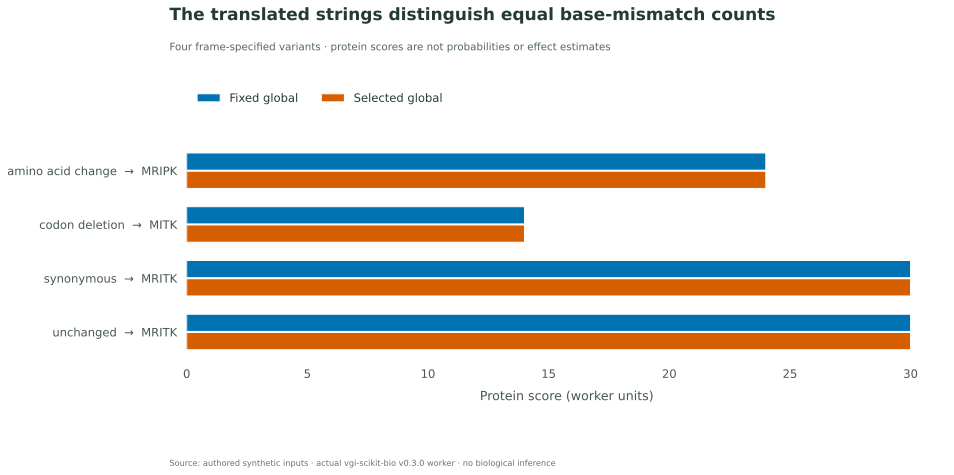

In [11]:
display(proteins)
syn = proteins[proteins.variant == "synonymous"].iloc[0]
changed = proteins[proteins.variant == "amino_acid_change"].iloc[0]
prose(
    f"The synonymous string translates to **{syn.alternative_protein}**, identical to its reference **{syn.reference_protein}**. The other one-base variant translates to **{changed.alternative_protein}**. One base mismatch therefore does not determine protein equality. These are exact string transformations under a chosen frame, not predictions of functional impact."
)
fig, ax = plt.subplots(figsize=(12, 7))
y = np.arange(len(proteins))
ax.barh(y - 0.17, proteins.global_protein_score, height=0.32, color="#0072B2", label="Fixed global")
ax.barh(
    y + 0.17,
    proteins.selected_score,
    height=0.32,
    color="#D55E00",
    label=f"Selected {ALIGNMENT_MODE}",
)
ax.set_yticks(
    y, [f"{r.variant.replace('_', ' ')}  →  {r.alternative_protein}" for r in proteins.itertuples()]
)
ax.invert_yaxis()
ax.set_xlabel("Protein score (worker units)")
ax.grid(axis="y", visible=False)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.09, 0.82), ncol=2)
finish(
    fig,
    "The translated strings distinguish equal base-mismatch counts",
    "Four frame-specified variants · protein scores are not probabilities or effect estimates",
    SOURCE,
    name=f"protein-{ALIGNMENT_MODE}",
)

### Unknown frame is a separate uncertainty

`translate_six_frames` enumerates three offsets on each strand. We display all six candidate strings for the fixed reference, along with their lengths and stop symbols. Its +1 result must match the stipulated translation used above. Enumeration supplies possibilities; it does not choose a gene or discover a true frame.

In [12]:
%%sql
CREATE TABLE frames AS SELECT * FROM skbio.sequence.translate_six_frames(
 (SELECT 'reference' AS read_id,'ATGCGGATTACAAAA' AS seq),id := 'read_id');
SELECT read_id,frame,protein,length(protein) AS amino_acid_symbols,
 length(protein)-length(replace(protein,'*','')) AS stop_symbols
FROM frames ORDER BY frame;

,read_id,frame,protein,amino_acid_symbols,stop_symbols
0,reference,+1,MRITK,5,0
1,reference,+2,CGLQ,4,0
2,reference,+3,ADYK,4,0
3,reference,-1,FCNPH,5,0
4,reference,-2,FVIR,4,0
5,reference,-3,L*SA,4,1


In [13]:
%%sql checks <<
SELECT 'five_pairs_retained' AS check_name,count(*)=5 AS passed FROM positions
UNION ALL SELECT 'equal_length_identity',bool_and(matches+mismatches=reference_bases AND abs(hamming_fraction-mismatches/reference_bases)<1e-12) FROM positions WHERE reference_bases=alternative_bases
UNION ALL SELECT 'unequal_length_unavailable',count(*)=2 AND bool_and(matches IS NULL AND mismatches IS NULL AND hamming_fraction IS NULL) FROM positions WHERE reference_bases<>alternative_bases
UNION ALL SELECT 'dna_global_scalar_agrees',bool_and(abs(g.score-p.global_dna_score)<1e-12) FROM dna_global g JOIN positions p USING(variant)
UNION ALL SELECT 'aligned_lengths_match',bool_and(length=length(aligned_1) AND length=length(aligned_2)) FROM dna_selected
UNION ALL SELECT 'protein_global_scalar_agrees',bool_and(abs(g.score-p.global_protein_score)<1e-12) FROM protein_global g JOIN protein_summary p USING(variant)
UNION ALL SELECT 'synonymous_translation',reference_protein=alternative_protein FROM translated WHERE variant='synonymous'
UNION ALL SELECT 'changed_translation',reference_protein<>alternative_protein FROM translated WHERE variant='amino_acid_change'
UNION ALL SELECT 'six_frames',count(*)=6 AND count(DISTINCT frame)=6 FROM frames
UNION ALL SELECT 'plus_one_agrees',protein=(SELECT reference_protein FROM translated LIMIT 1) FROM frames WHERE frame='+1';

In [14]:
display(checks)
assert checks.passed.all()
prose(
    f"All **{len(checks)} checks** pass. The six-frame table remains fixed when alignment mode changes: frame enumeration and selecting a matching alignment region are different operations."
)
Path("artifacts/analysis-03.json").write_text(
    json.dumps(
        {
            "mode": ALIGNMENT_MODE,
            "alignment": alignment.to_dict("records"),
            "proteins": proteins.to_dict("records"),
            "checks": checks.to_dict("records"),
        },
        indent=2,
    )
)

,check_name,passed
0,five_pairs_retained,True
1,equal_length_identity,True
2,unequal_length_unavailable,True
3,dna_global_scalar_agrees,True
4,aligned_lengths_match,True
5,protein_global_scalar_agrees,True
6,synonymous_translation,True
7,changed_translation,True
8,six_frames,True
9,plus_one_agrees,True


All **10 checks** pass. The six-frame table remains fixed when alignment mode changes: frame enumeration and selecting a matching alignment region are different operations.

4264

### Experiment: select local alignments

Change `ALIGNMENT_MODE` from **"global" to "local"**. Inspect the flanked/deletion strings and the selected alignment-column counts. Global scalar scores, Hamming results, input translations and six-frame candidates must remain fixed. Selected spans and scores may change. The unchanged pair also changes score because local mode rewards each match by +2 instead of +1; do not attribute every score change to a shorter span or an improved match.

The [global nucleotide defaults](https://scikit.bio/docs/latest/generated/skbio.alignment.global_pairwise_align_nucleotide.html) and [local nucleotide defaults](https://scikit.bio/docs/latest/generated/skbio.alignment.local_pairwise_align_nucleotide.html) document these distinct scoring settings. Ties may permit multiple alignments; this worker returns one. No alignment score or shared string alone establishes homology, identity or biological consequence.

In [15]:
session.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-scikit-bio](https://github.com/Query-farm/vgi-scikit-bio)
